<a href="https://colab.research.google.com/github/RohanSNikam/Logistics-Delivery-Time-Analysis/blob/main/notebooks/Week_4_logistics_delivery_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    TimeSeriesSplit,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Week3_Logistics_Preprocessed.xlsx to Week3_Logistics_Preprocessed.xlsx


In [3]:
df = pd.read_excel(
    'Week3_Logistics_Preprocessed.xlsx',
    sheet_name='Cleaned_Data'
)

In [4]:
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (985, 17)


,order_id,order_date,origin_city,destination_city,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status,inventory_qty,year,month,day
0,LOG100555,2026-01-15,Nashik,Nagpur,105.5,High,Clear,Bike,13550.21,180,203.0,535.34,Delayed,19.0,2026,1,15
1,LOG100331,2026-01-13,Satara,Aurangabad,440.2,Medium,Clear,Truck,5898.03,541,602.0,1337.10,Delayed,103.0,2026,1,13
2,LOG100974,2026-07-20,Satara,Aurangabad,19.1,Medium,Foggy,Van,20909.87,388,459.0,241.92,Delayed,99.0,2026,7,20
3,LOG100157,2026-06-26,Ahmednagar,Mumbai,407.9,High,Clear,Bike,19699.13,486,552.0,1705.47,Delayed,78.0,2026,6,26
4,LOG100322,2026-10-04,Satara,Thane,234.2,Medium,Clear,Truck,4527.08,342,455.0,826.18,Delayed,76.0,2026,10,4


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (985, 17)

Column Names:
['order_id', 'order_date', 'origin_city', 'destination_city', 'distance_km', 'traffic_level', 'weather', 'vehicle_type', 'order_value_inr', 'promised_delivery_minutes', 'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status', 'inventory_qty', 'year', 'month', 'day']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   order_id                   985 non-null    object        
 1   order_date                 985 non-null    datetime64[ns]
 2   origin_city                985 non-null    object        
 3   destination_city           985 non-null    object        
 4   distance_km                985 non-null    float64       
 5   traffic_level              985 non-null    object        
 6   weather                    985 non-null    object        
 7   vehicle_type               985 non-null    object        
 8   order_value_inr            985 non-null    float64       
 9   promised_delivery_minutes  985 non-null    int64         
 10  actual_delivery_minutes    985 non-null    float64       
 11  delivery_cost_inr          985 non-null    float64       
 12  delivery

In [7]:
df.describe()

,order_date,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty,year,month,day
count,985,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.0,985.000000,985.000000
mean,2026-06-03 09:37:27.715736064,265.088731,12036.412985,493.669036,625.486802,1086.689716,74.797462,2026.0,5.603046,15.277157
min,2026-01-01 00:00:00,5.000000,276.890000,60.000000,5.000000,5.000000,0.000000,2026.0,1.000000,1.000000
25%,2026-03-19 00:00:00,141.400000,5700.420000,285.000000,342.000000,626.330000,39.000000,2026.0,3.000000,8.000000
50%,2026-06-10 00:00:00,276.800000,11505.710000,501.000000,586.000000,1085.590000,75.000000,2026.0,6.000000,15.000000
75%,2026-08-15 00:00:00,385.900000,18200.280000,711.000000,865.000000,1450.300000,112.000000,2026.0,8.000000,23.000000
max,2026-10-27 00:00:00,752.650000,24988.840000,896.000000,1649.500000,2686.255000,221.500000,2026.0,10.000000,31.000000
std,NaN,143.610489,7202.635962,242.841730,358.249882,552.610651,42.795100,0.0,2.840222,8.693361


In [8]:
df.dtypes

,0
order_id,object
order_date,datetime64[ns]
origin_city,object
destination_city,object
distance_km,float64
traffic_level,object
weather,object
vehicle_type,object
order_value_inr,float64
promised_delivery_minutes,int64


In [9]:
print(df.isnull().sum())

order_id                     0
order_date                   0
origin_city                  0
destination_city             0
distance_km                  0
traffic_level                0
weather                      0
vehicle_type                 0
order_value_inr              0
promised_delivery_minutes    0
actual_delivery_minutes      0
delivery_cost_inr            0
delivery_status              0
inventory_qty                0
year                         0
month                        0
day                          0
dtype: int64


In [10]:
print(df['actual_delivery_minutes'].describe())

count     985.000000
mean      625.486802
std       358.249882
min         5.000000
25%       342.000000
50%       586.000000
75%       865.000000
max      1649.500000
Name: actual_delivery_minutes, dtype: float64


In [11]:
print(
    "Zero or Negative Delivery Times:",
    (df['actual_delivery_minutes'] <= 0).sum()
)

Zero or Negative Delivery Times: 0


In [12]:
df['order_date'] = pd.to_datetime(
    df['order_date'],
    errors='coerce'
)

print("Invalid Dates:", df['order_date'].isnull().sum())

Invalid Dates: 0


In [13]:
features = [
    'distance_km',
    'traffic_level',
    'weather',
    'vehicle_type',
    'order_value_inr',
    'promised_delivery_minutes',
    'inventory_qty',
    'origin_city',
    'destination_city'
]

In [14]:
target = 'actual_delivery_minutes'

In [15]:
print("Available Features:")

for col in features:
    print(col, ":", col in df.columns)

print("\nTarget Available:", target in df.columns)

Available Features:
distance_km : True
traffic_level : True
weather : True
vehicle_type : True
order_value_inr : True
promised_delivery_minutes : True
inventory_qty : True
origin_city : True
destination_city : True

Target Available: True


In [16]:
df['order_month'] = df['order_date'].dt.month

In [17]:
df['order_day'] = df['order_date'].dt.day

In [18]:
df['order_weekday'] = df['order_date'].dt.dayofweek

In [19]:
df[
    ['order_date',
     'order_month',
     'order_day',
     'order_weekday']
].head(10)

,order_date,order_month,order_day,order_weekday
0,2026-01-15,1,15,3
1,2026-01-13,1,13,1
2,2026-07-20,7,20,0
3,2026-06-26,6,26,4
4,2026-10-04,10,4,6
5,2026-07-03,7,3,4
6,2026-08-11,8,11,1
7,2026-02-05,2,5,3
8,2026-09-22,9,22,1
9,2026-07-09,7,9,3


In [20]:
features.extend([
    'order_month',
    'order_day',
    'order_weekday'
])

print(features)

['distance_km', 'traffic_level', 'weather', 'vehicle_type', 'order_value_inr', 'promised_delivery_minutes', 'inventory_qty', 'origin_city', 'destination_city', 'order_month', 'order_day', 'order_weekday']


In [21]:
model_df = df.copy()

model_df = model_df.dropna(
    subset=['order_date', 'actual_delivery_minutes']
)

model_df = model_df.sort_values(
    'order_date'
).reset_index(drop=True)

In [22]:
X = model_df[features]

y = model_df[target]

In [23]:
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [24]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (788, 12)
Testing Data: (197, 12)
Training Target: (788,)
Testing Target: (197,)


In [26]:
print("Training Start:",
      model_df.iloc[:split_index]['order_date'].min())

print("Training End:",
      model_df.iloc[:split_index]['order_date'].max())

print("Testing Start:",
      model_df.iloc[split_index:]['order_date'].min())

print("Testing End:",
      model_df.iloc[split_index:]['order_date'].max())

Training Start: 2026-01-01 00:00:00
Training End: 2026-08-29 00:00:00
Testing Start: 2026-08-29 00:00:00
Testing End: 2026-10-27 00:00:00


In [27]:
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

In [28]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['distance_km', 'order_value_inr', 'promised_delivery_minutes', 'inventory_qty']

Categorical Features:
['traffic_level', 'weather', 'vehicle_type', 'origin_city', 'destination_city']


In [29]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [30]:
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [32]:
from sklearn.linear_model import LinearRegression

In [33]:
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

In [34]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['distance_km',
                                                   'order_value_inr',
                                                   'promised_delivery_minutes',
                                                   'inventory_qty']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['traffic_level', 'weather',
                                                   'vehicle_type',
                                                   'origin_city',
                                                   'destination_city'])])),
                ('model', LinearRegression())])

In [35]:
linear_predictions = linear_model.predict(X_test)

In [36]:
linear_results = pd.DataFrame({
    'Actual_Delivery_Time': y_test.values,
    'Predicted_Delivery_Time': linear_predictions
})

linear_results.head(10)

,Actual_Delivery_Time,Predicted_Delivery_Time
0,86.0,234.576329
1,143.0,197.736284
2,82.0,72.749185
3,1102.0,985.616499
4,1168.0,1092.450164
5,1649.5,1302.550744
6,281.0,385.434596
7,440.0,405.484525
8,1347.0,1198.093725
9,442.0,349.826004


In [37]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression Results")

print("MAE:", round(linear_mae, 2))
print("MSE:", round(linear_mse, 2))
print("RMSE:", round(linear_rmse, 2))
print("R2 Score:", round(linear_r2, 4))

Linear Regression Results
MAE: 100.99
MSE: 15734.2
RMSE: 125.44
R2 Score: 0.8753


In [38]:
from sklearn.tree import DecisionTreeRegressor

In [39]:
tree_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(
            max_depth=5,
            random_state=42
        ))
    ]
)

In [40]:
tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['distance_km',
                                                   'order_value_inr',
                                                   'promised_delivery_minutes',
                                                   'inventory_qty']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['traffic_level', 'weather',
                                                   'vehicle_type',
                                                   'origin_city',
                                                   'destination_city'])])),
                ('model', DecisionTreeRegressor(max_depth=5, random_state=42))])

In [42]:
tree_predictions = tree_model.predict(X_test)

In [43]:
tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

tree_mse = mean_squared_error(
    y_test,
    tree_predictions
)

tree_rmse = np.sqrt(tree_mse)

tree_r2 = r2_score(
    y_test,
    tree_predictions
)

print("Decision Tree Results")

print("MAE:", round(tree_mae, 2))
print("MSE:", round(tree_mse, 2))
print("RMSE:", round(tree_rmse, 2))
print("R2 Score:", round(tree_r2, 4))

Decision Tree Results
MAE: 101.0
MSE: 27010.61
RMSE: 164.35
R2 Score: 0.7858


In [44]:
from sklearn.ensemble import RandomForestRegressor

In [45]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=200,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [46]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['distance_km',
                                                   'order_value_inr',
                                                   'promised_delivery_minutes',
                                                   'inventory_qty']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['traffic_level', 'weather',
                                                   'vehicle_type',
                                                   'origin_city',
                                                   'destination_city'])])),
                ('model',
                 RandomForestRegressor(max_depth=10, n_estimators=200,
                                       n_jobs=-1, random_state=42))])

In [48]:
rf_predictions = rf_model.predict(X_test)

In [49]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_mse = mean_squared_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest Results")

print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Results
MAE: 86.07
MSE: 13958.25
RMSE: 118.15
R2 Score: 0.8893


In [50]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        linear_mae,
        tree_mae,
        rf_mae
    ],

    'MSE': [
        linear_mse,
        tree_mse,
        rf_mse
    ],

    'RMSE': [
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],

    'R2_Score': [
        linear_r2,
        tree_r2,
        rf_r2
    ]
})

model_comparison

,Model,MAE,MSE,RMSE,R2_Score
0,Linear Regression,100.990384,15734.200151,125.436040,0.875251
1,Decision Tree,100.998751,27010.608261,164.349044,0.785846
2,Random Forest,86.066024,13958.254287,118.145056,0.889332


In [51]:
model_comparison.sort_values(
    by='MAE',
    ascending=True
)

,Model,MAE,MSE,RMSE,R2_Score
2,Random Forest,86.066024,13958.254287,118.145056,0.889332
0,Linear Regression,100.990384,15734.200151,125.436040,0.875251
1,Decision Tree,100.998751,27010.608261,164.349044,0.785846


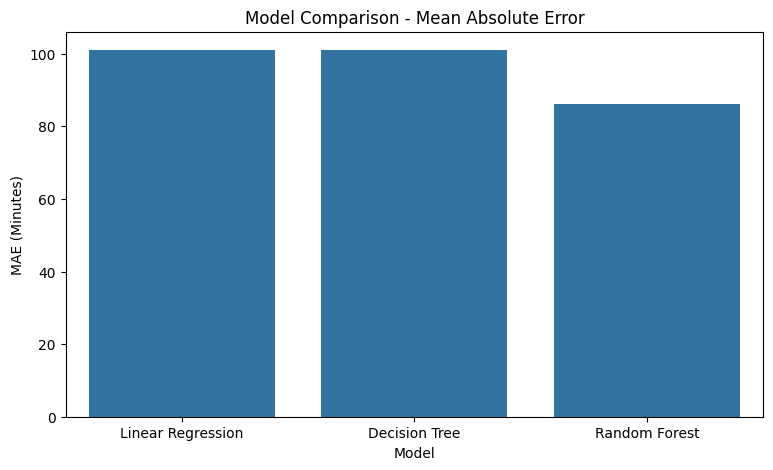

In [52]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='MAE'
)

plt.title('Model Comparison - Mean Absolute Error')
plt.ylabel('MAE (Minutes)')

plt.show()

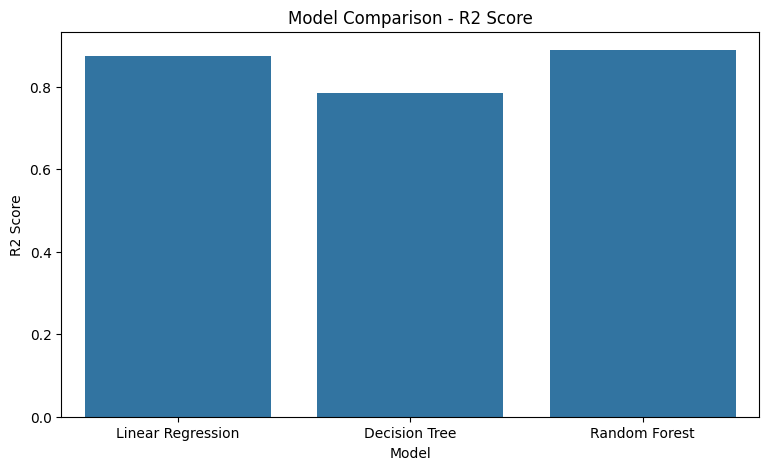

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='R2_Score'
)

plt.title('Model Comparison - R2 Score')
plt.ylabel('R2 Score')

plt.show()

In [54]:
from sklearn.model_selection import (
    TimeSeriesSplit,
    cross_val_score
)

In [55]:
tscv = TimeSeriesSplit(n_splits=5)

In [56]:
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

In [57]:
cv_mae = -cv_scores

print("Cross Validation MAE Scores:")
print(cv_mae)

print("\nAverage CV MAE:",
      round(cv_mae.mean(), 2))

print("Standard Deviation:",
      round(cv_mae.std(), 2))

Cross Validation MAE Scores:
[155.86972552 102.9439333   84.75762223 112.79709272  84.22722174]

Average CV MAE: 108.12
Standard Deviation: 26.25


**Hyperparameter Tuning**

In [58]:
from sklearn.model_selection import GridSearchCV

In [59]:
param_grid = {
    'model__n_estimators': [100, 200],

    'model__max_depth': [5, 10, None],

    'model__min_samples_split': [2, 5],

    'model__min_samples_leaf': [1, 3]
}

In [60]:
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

In [61]:
grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['distance_km',
                                                                          'order_value_inr',
                                                                          'promised_delivery_minutes',
                                                                          'inventory_qty']),
                                                                        ('cat',
                                                                         Pipelin...
                                                                         ['traffic_level',
                                                                          'weather',
                                                                          'vehicle_type',
                                                                          'origin_city',
                                                                          'destination_city'])])),
                                       ('model',
                                        RandomForestRegressor(max_depth=10,
                                                              n_estimators=200,
                                                              n_jobs=-1,
                                                              random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [5, 10, None],
                         'model__min_samples_leaf': [1, 3],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='neg_mean_absolute_error', verbose=1)

In [62]:
print("Best Parameters:")

print(grid_search.best_params_)

Best Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__min_samples_split': 2, 'model__n_estimators': 100}


In [63]:
print(
    "Best CV MAE:",
    round(-grid_search.best_score_, 2)
)

Best CV MAE: 101.01


In [64]:
best_model = grid_search.best_estimator_

In [65]:
tuned_predictions = best_model.predict(X_test)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_mse = mean_squared_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(tuned_mse)

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

print("Tuned Random Forest Results")

print("MAE:", round(tuned_mae, 2))
print("MSE:", round(tuned_mse, 2))
print("RMSE:", round(tuned_rmse, 2))
print("R2 Score:", round(tuned_r2, 4))

Tuned Random Forest Results
MAE: 87.0
MSE: 14002.33
RMSE: 118.33
R2 Score: 0.889


In [66]:
final_comparison = pd.concat([
    model_comparison,
    pd.DataFrame([{
        'Model': 'Tuned Random Forest',
        'MAE': tuned_mae,
        'MSE': tuned_mse,
        'RMSE': tuned_rmse,
        'R2_Score': tuned_r2
    }])
], ignore_index=True)

final_comparison.sort_values(
    by='MAE',
    ascending=True
)

,Model,MAE,MSE,RMSE,R2_Score
2,Random Forest,86.066024,13958.254287,118.145056,0.889332
3,Tuned Random Forest,86.999198,14002.332004,118.331450,0.888982
0,Linear Regression,100.990384,15734.200151,125.436040,0.875251
1,Decision Tree,100.998751,27010.608261,164.349044,0.785846


**Feature Importance Analysis**

In [67]:
from sklearn.inspection import permutation_importance

In [68]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

In [69]:
importance_df = pd.DataFrame({
    'Feature': X_test.columns,

    'Importance': importance.importances_mean,

    'Standard_Deviation': importance.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance,Standard_Deviation
5,promised_delivery_minutes,2.938375e+02,1.223116e+01
1,traffic_level,5.423585e+01,6.471428e+00
2,weather,1.026321e+01,2.298773e+00
8,destination_city,1.691252e+00,7.122985e-01
10,order_day,-5.684342e-15,1.927654e-14
9,order_month,-7.105427e-15,1.456179e-14
11,order_weekday,-8.526513e-15,1.705303e-14
3,vehicle_type,-2.619833e-01,3.380463e-01
7,origin_city,-3.414371e-01,4.766235e-01
0,distance_km,-7.812059e-01,9.818589e-01


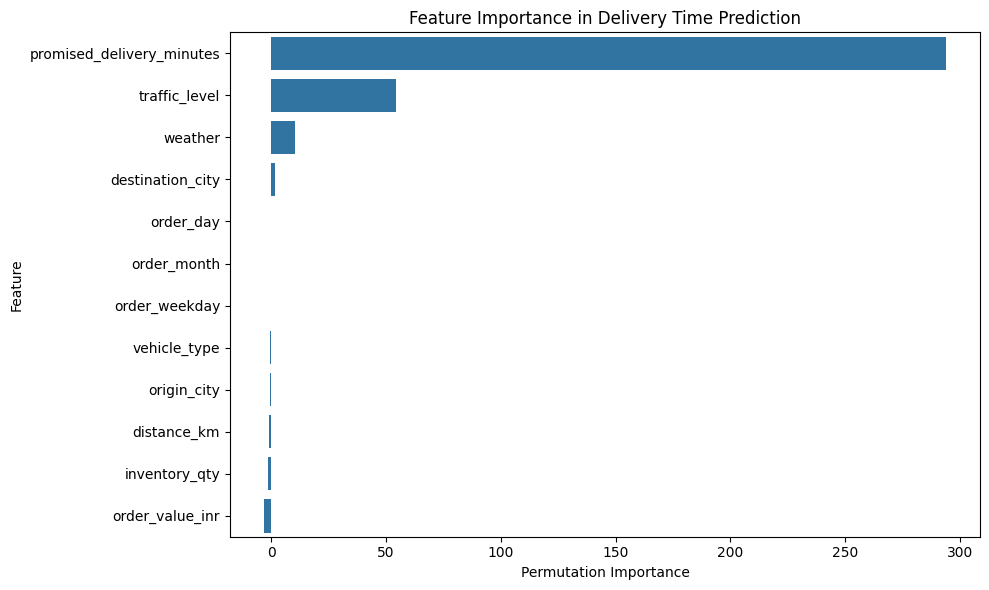

In [70]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance in Delivery Time Prediction')
plt.xlabel('Permutation Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

**Actual vs Predicted Visualization**

In [71]:
prediction_results = pd.DataFrame({
    'Actual': y_test.values,

    'Predicted': tuned_predictions
})

prediction_results['Error'] = (
    prediction_results['Actual'] -
    prediction_results['Predicted']
)

prediction_results.head(15)

,Actual,Predicted,Error
0,86.0,102.032855,-16.032855
1,143.0,131.941329,11.058671
2,82.0,97.492751,-15.492751
3,1102.0,928.300199,173.699801
4,1168.0,1106.240171,61.759829
5,1649.5,1304.046233,345.453767
6,281.0,275.331456,5.668544
7,440.0,395.123040,44.876960
8,1347.0,1099.287766,247.712234
9,442.0,365.366513,76.633487


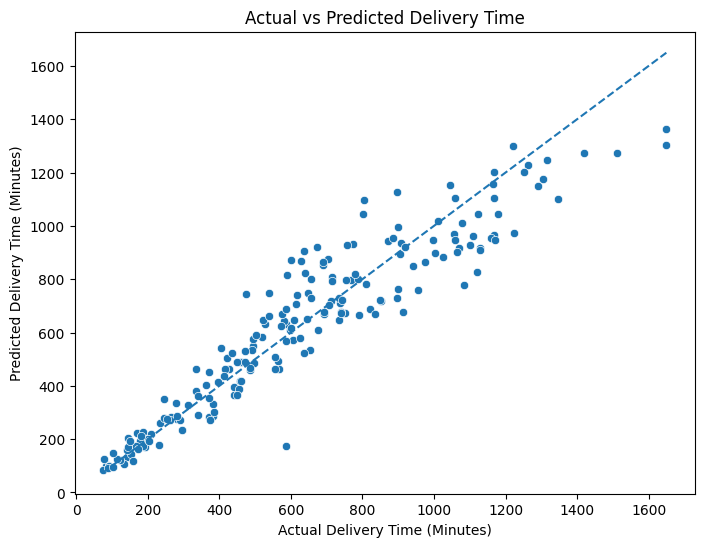

In [72]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=prediction_results,
    x='Actual',
    y='Predicted'
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted Delivery Time')

plt.xlabel('Actual Delivery Time (Minutes)')

plt.ylabel('Predicted Delivery Time (Minutes)')

plt.show()

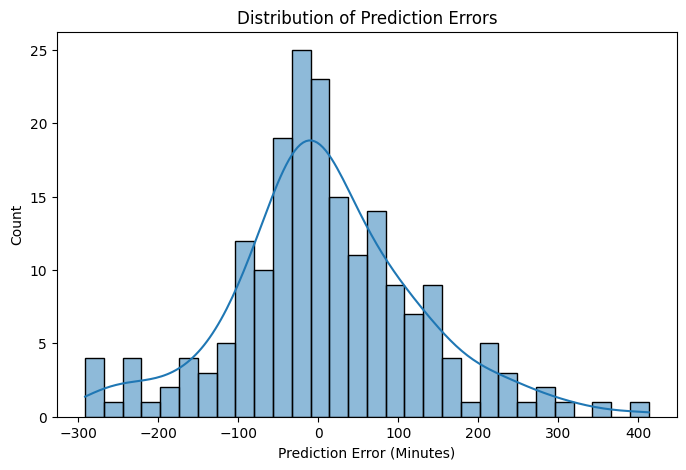

In [73]:
plt.figure(figsize=(8, 5))

sns.histplot(
    prediction_results['Error'],
    bins=30,
    kde=True
)

plt.title('Distribution of Prediction Errors')

plt.xlabel('Prediction Error (Minutes)')

plt.show()

**Predict Delivery Time for a New Order**

In [74]:
new_order = pd.DataFrame([{
    'distance_km': 150.0,
    'traffic_level': 'Medium',
    'weather': 'Clear',
    'vehicle_type': 'Truck',
    'order_value_inr': 12000.0,
    'promised_delivery_minutes': 300,
    'inventory_qty': 50,
    'origin_city': 'Pune',
    'destination_city': 'Mumbai',
    'order_month': 11,
    'order_day': 7,
    'order_weekday': 5
}])

new_order = new_order[features]

In [75]:
predicted_time = best_model.predict(new_order)

print(
    "Predicted Delivery Time:",
    round(predicted_time[0], 2),
    "Minutes"
)

Predicted Delivery Time: 322.35 Minutes


In [76]:
promised_time = 300

predicted_delay = (
    predicted_time[0] - promised_time
)

print("Predicted Delivery Time:",
      round(predicted_time[0], 2))

print("Promised Delivery Time:",
      promised_time)

print("Predicted Difference:",
      round(predicted_delay, 2),
      "Minutes")

if predicted_delay > 0:
    print("Prediction: Potential Delivery Delay")
else:
    print("Prediction: Expected On-Time Delivery")

Predicted Delivery Time: 322.35
Promised Delivery Time: 300
Predicted Difference: 22.35 Minutes
Prediction: Potential Delivery Delay


**Logistics Optimization**

In [77]:
optimization_df = X_test.copy()

optimization_df['Actual_Delivery_Time'] = (
    y_test.values
)

optimization_df['Predicted_Delivery_Time'] = (
    tuned_predictions
)

optimization_df['Promised_Time'] = (
    X_test['promised_delivery_minutes'].values
)

In [78]:
optimization_df['Predicted_Delay'] = (
    optimization_df['Predicted_Delivery_Time'] -
    optimization_df['Promised_Time']
)

In [79]:
def classify_risk(delay):

    if delay <= 0:
        return 'Low Risk'

    elif delay <= 30:
        return 'Medium Risk'

    else:
        return 'High Risk'

In [80]:
optimization_df['Risk_Level'] = (
    optimization_df['Predicted_Delay']
    .apply(classify_risk)
)

In [81]:
optimization_df[
    [
        'Actual_Delivery_Time',
        'Predicted_Delivery_Time',
        'Promised_Time',
        'Predicted_Delay',
        'Risk_Level'
    ]
].head(15)

,Actual_Delivery_Time,Predicted_Delivery_Time,Promised_Time,Predicted_Delay,Risk_Level
788,86.0,102.032855,77,25.032855,Medium Risk
789,143.0,131.941329,104,27.941329,Medium Risk
790,82.0,97.492751,86,11.492751,Medium Risk
791,1102.0,928.300199,826,102.300199,High Risk
792,1168.0,1106.240171,763,343.240171,High Risk
793,1649.5,1304.046233,860,444.046233,High Risk
794,281.0,275.331456,195,80.331456,High Risk
795,440.0,395.123040,270,125.123040,High Risk
796,1347.0,1099.287766,878,221.287766,High Risk
797,442.0,365.366513,311,54.366513,High Risk


In [82]:
risk_summary = (
    optimization_df['Risk_Level']
    .value_counts()
)

print(risk_summary)

Risk_Level
High Risk      153
Low Risk        23
Medium Risk     21
Name: count, dtype: int64


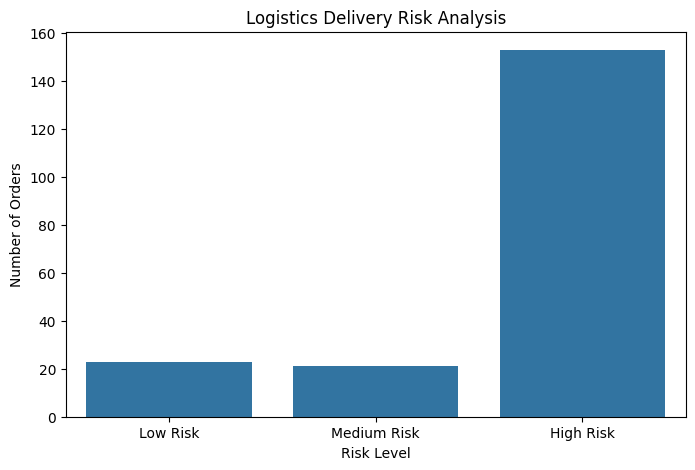

In [83]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=optimization_df,
    x='Risk_Level',
    order=['Low Risk', 'Medium Risk', 'High Risk']
)

plt.title('Logistics Delivery Risk Analysis')

plt.xlabel('Risk Level')

plt.ylabel('Number of Orders')

plt.show()

# **Save the Best Machine Learning Model**

In [84]:
import joblib

In [85]:
joblib.dump(
    best_model,
    'best_delivery_time_model.pkl'
)

['best_delivery_time_model.pkl']

In [86]:
import os

print(os.path.exists(
    'best_delivery_time_model.pkl'
))

True


In [87]:
from google.colab import files

files.download(
    'best_delivery_time_model.pkl'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Export Final Results to Excel**

In [88]:
with pd.ExcelWriter(
    'Week4_Logistics_ML_Results.xlsx'
) as writer:

    model_comparison.to_excel(
        writer,
        sheet_name='Model_Comparison',
        index=False
    )

    final_comparison.to_excel(
        writer,
        sheet_name='Final_Comparison',
        index=False
    )

    prediction_results.to_excel(
        writer,
        sheet_name='Predictions',
        index=False
    )

    importance_df.to_excel(
        writer,
        sheet_name='Feature_Importance',
        index=False
    )

    optimization_df.to_excel(
        writer,
        sheet_name='Optimization',
        index=False
    )

    pd.DataFrame({
        'Best_Parameters': [
            str(grid_search.best_params_)
        ],
        'Best_CV_MAE': [
            -grid_search.best_score_
        ],
        'Test_MAE': [
            tuned_mae
        ],
        'Test_RMSE': [
            tuned_rmse
        ],
        'Test_R2': [
            tuned_r2
        ]
    }).to_excel(
        writer,
        sheet_name='Best_Model_Summary',
        index=False
    )

In [89]:
files.download(
    'Week4_Logistics_ML_Results.xlsx'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Save Visualization Images**

In [90]:
from pathlib import Path

output_dir = Path('Week4_Outputs')

figures_dir = output_dir / 'figures'

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [91]:
plt.savefig(
    figures_dir / 'model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [92]:
import shutil

shutil.make_archive(
    'Week4_Visualization_Outputs',
    'zip',
    output_dir
)

files.download(
    'Week4_Visualization_Outputs.zip'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>